sp500 1950-01-03 2026-10-14 19318 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
sp500 // DCA: 8,251,970 // SMA50: -0.21% // SMA100: -0.87% // SMA200: -1.37% // average n=2-200: -0.75% // best n: 10 +0.13% // worst n: 182 -1.89% // lengths that beat DCA: 11 of 199
   group means vs DCA: 1-20: +0.00% | 21-40: -0.14% | 41-60: -0.16% | 61-80: -0.58% | 81-100: -0.95% | 101-120: -1.13% | 121-140: -0.91% | 141-160: -0.78% | 161-180: -1.28% | 181-200: -1.49% | 
sp500 // top 10 SMA lengths by final amount (sma_1 is DCA)
   rank  sma         final amount
      1  sma_10        8,262,893
      2  sma_9         8,259,227
      3  sma_11        8,257,011
      4  sma_12        8,254,553
      5  sma_16        8,254,354
      6  sma_8         8,253,492
      7  sma_3         8,253,489
      8  sma_20        8,252,980
      9  sma_22        8,252,466
     10  sma_21        8,252,246
nasdaq_comp 1971-02-05 2026-10-14 14040 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0

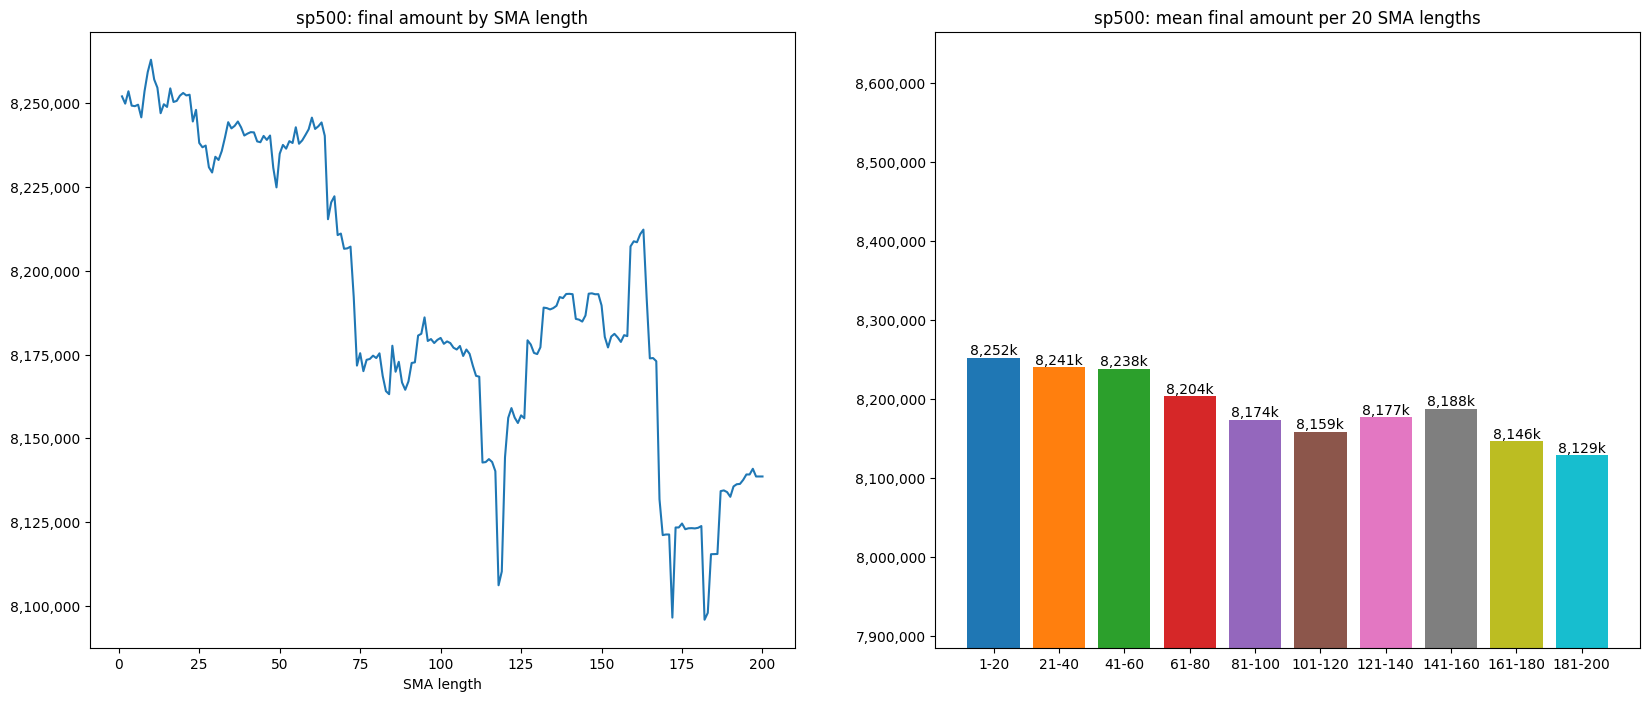

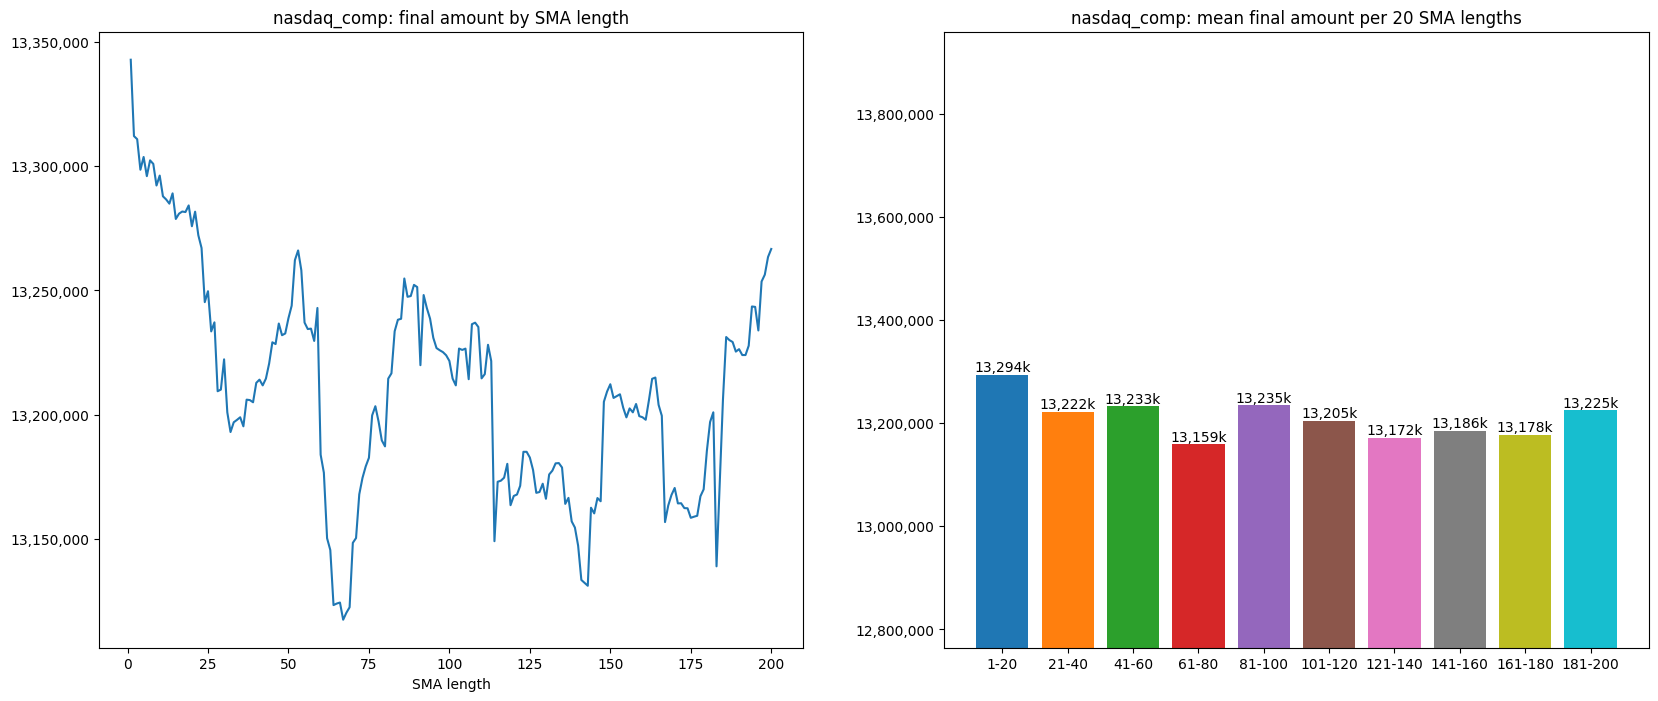

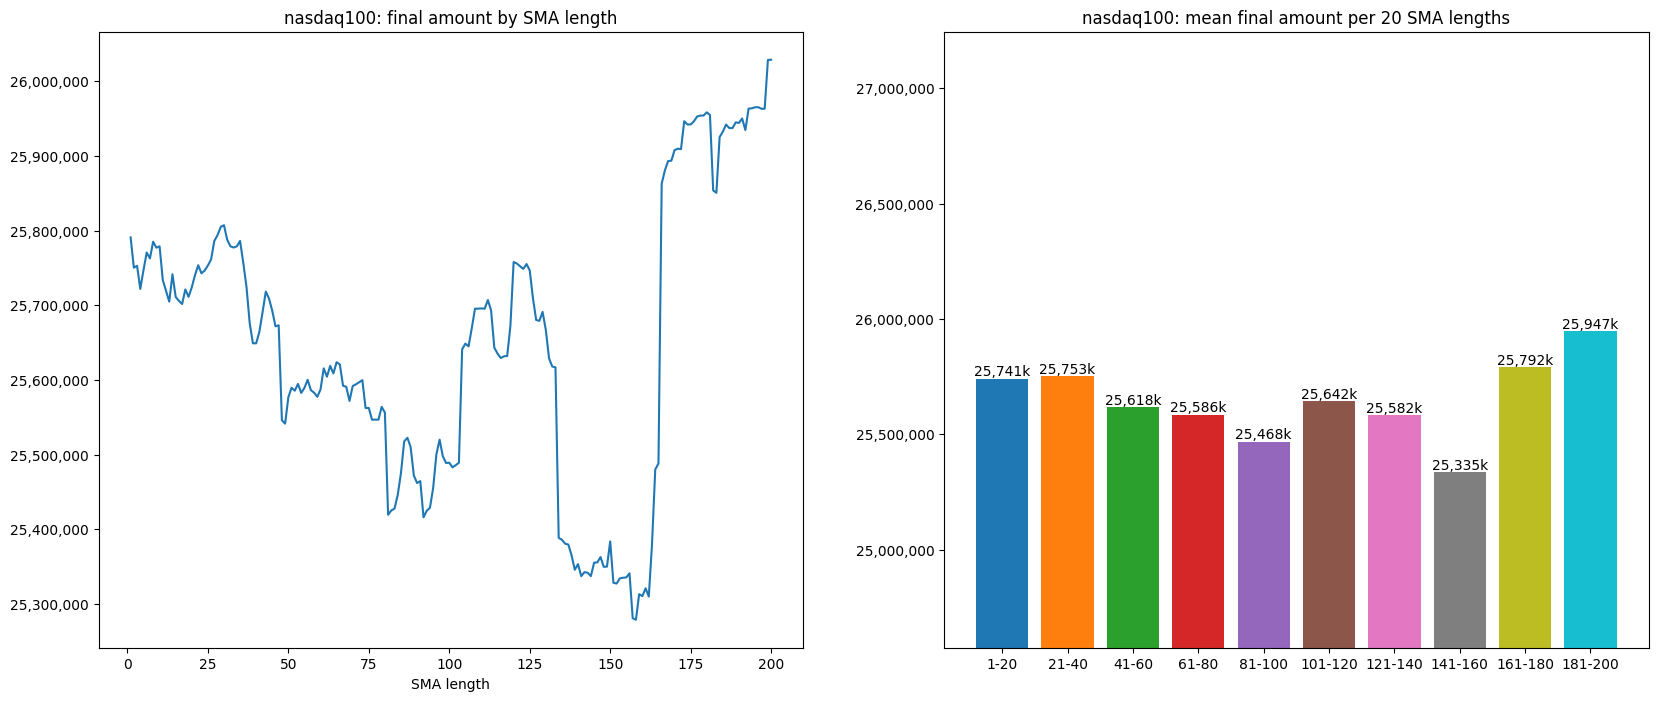

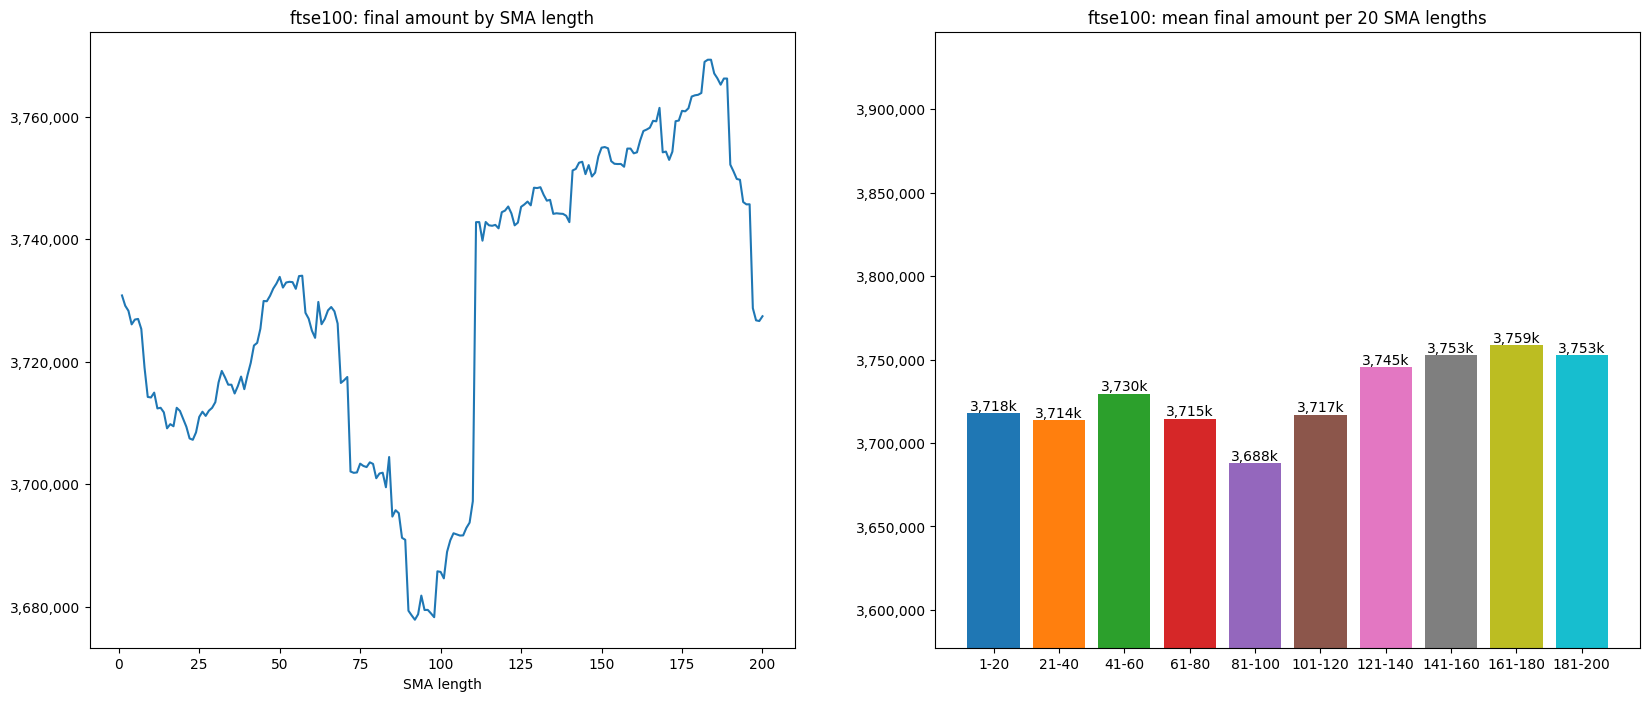

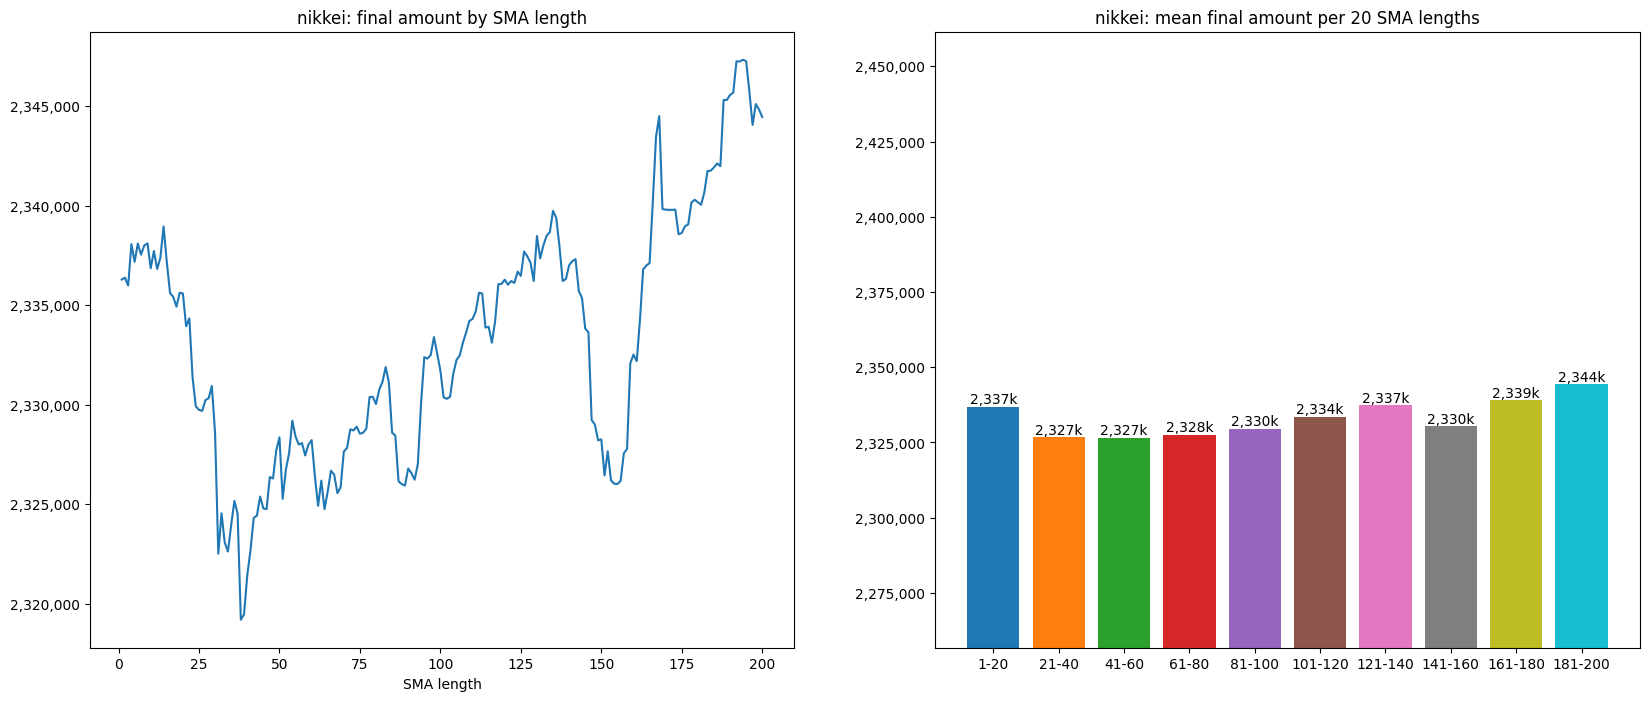

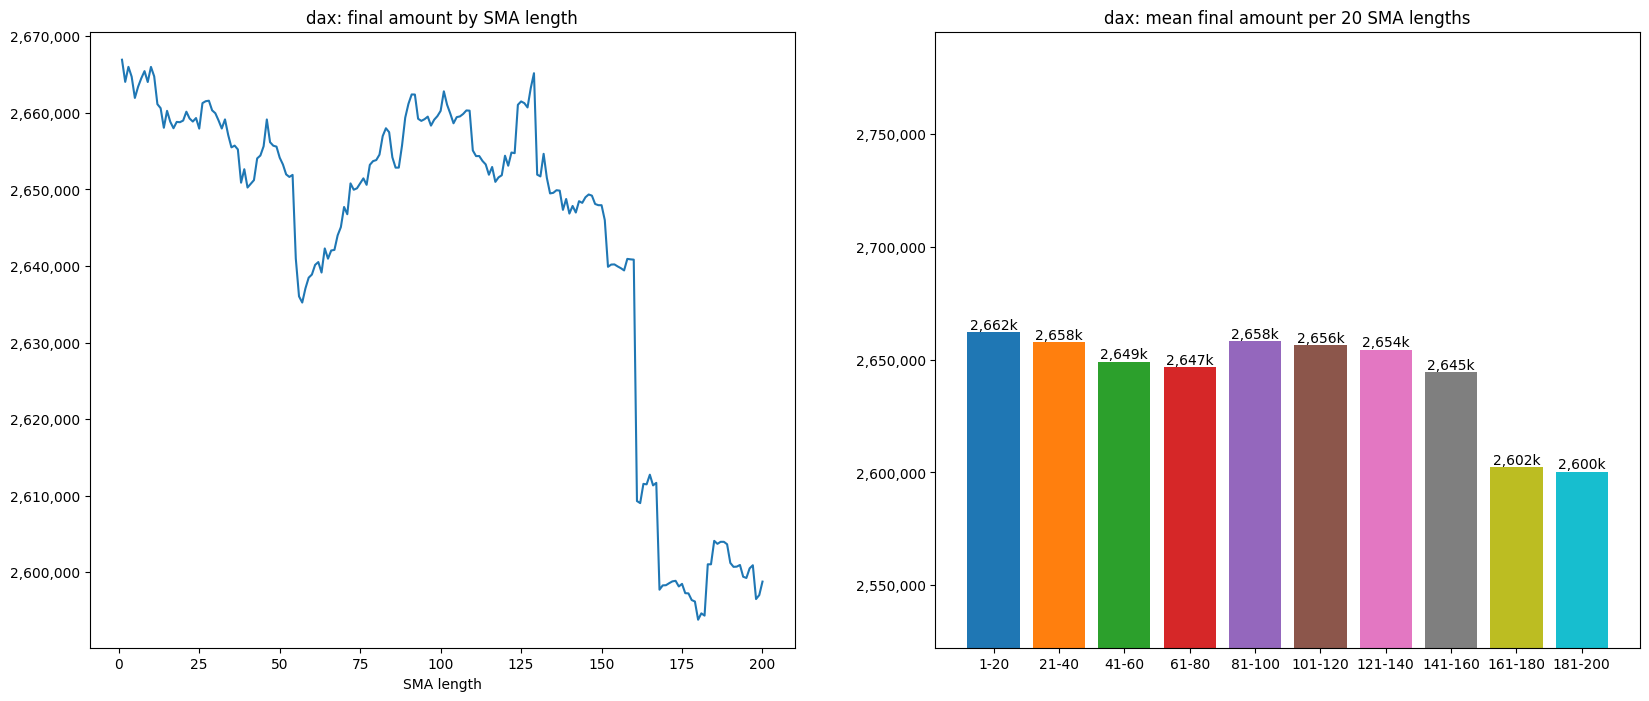

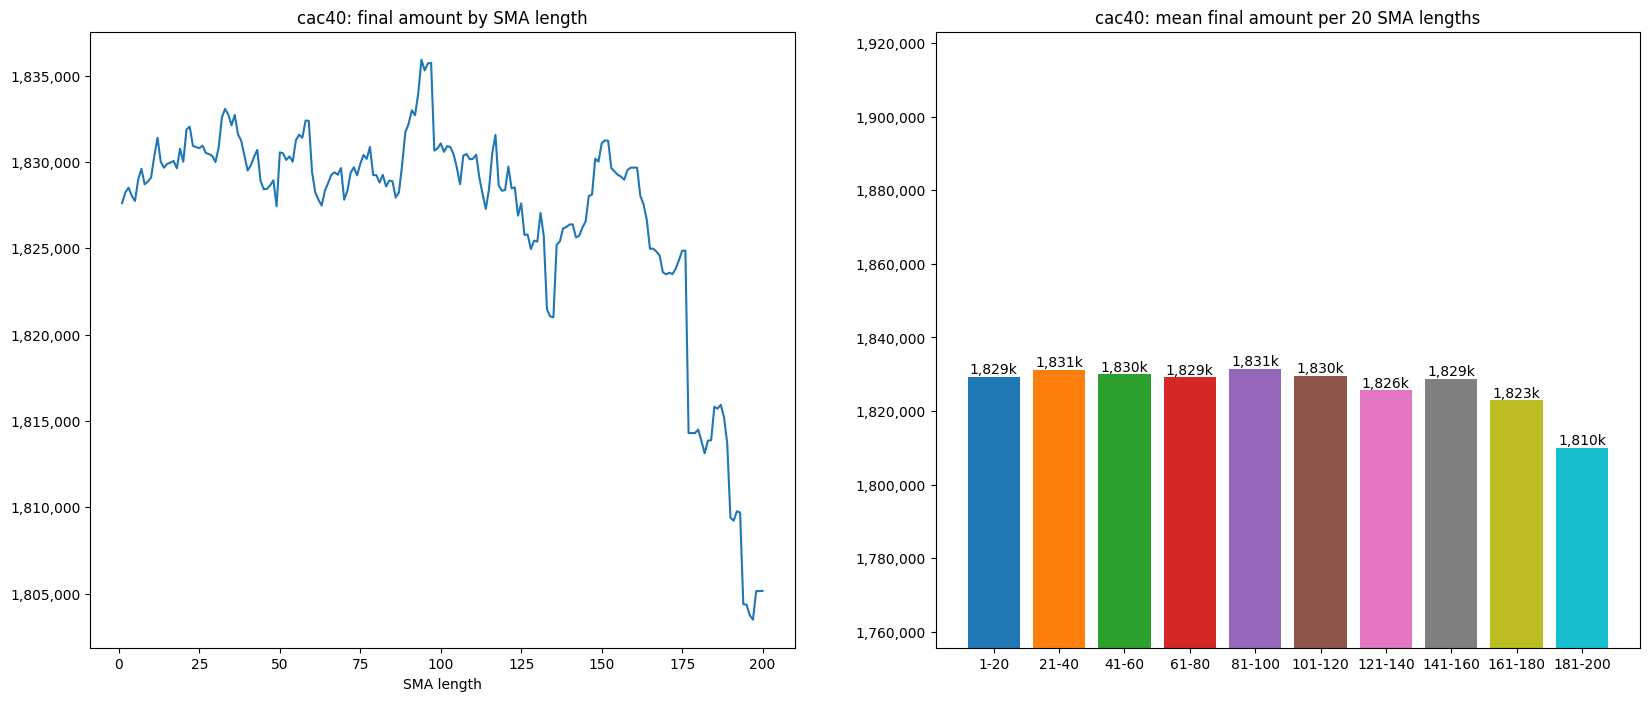

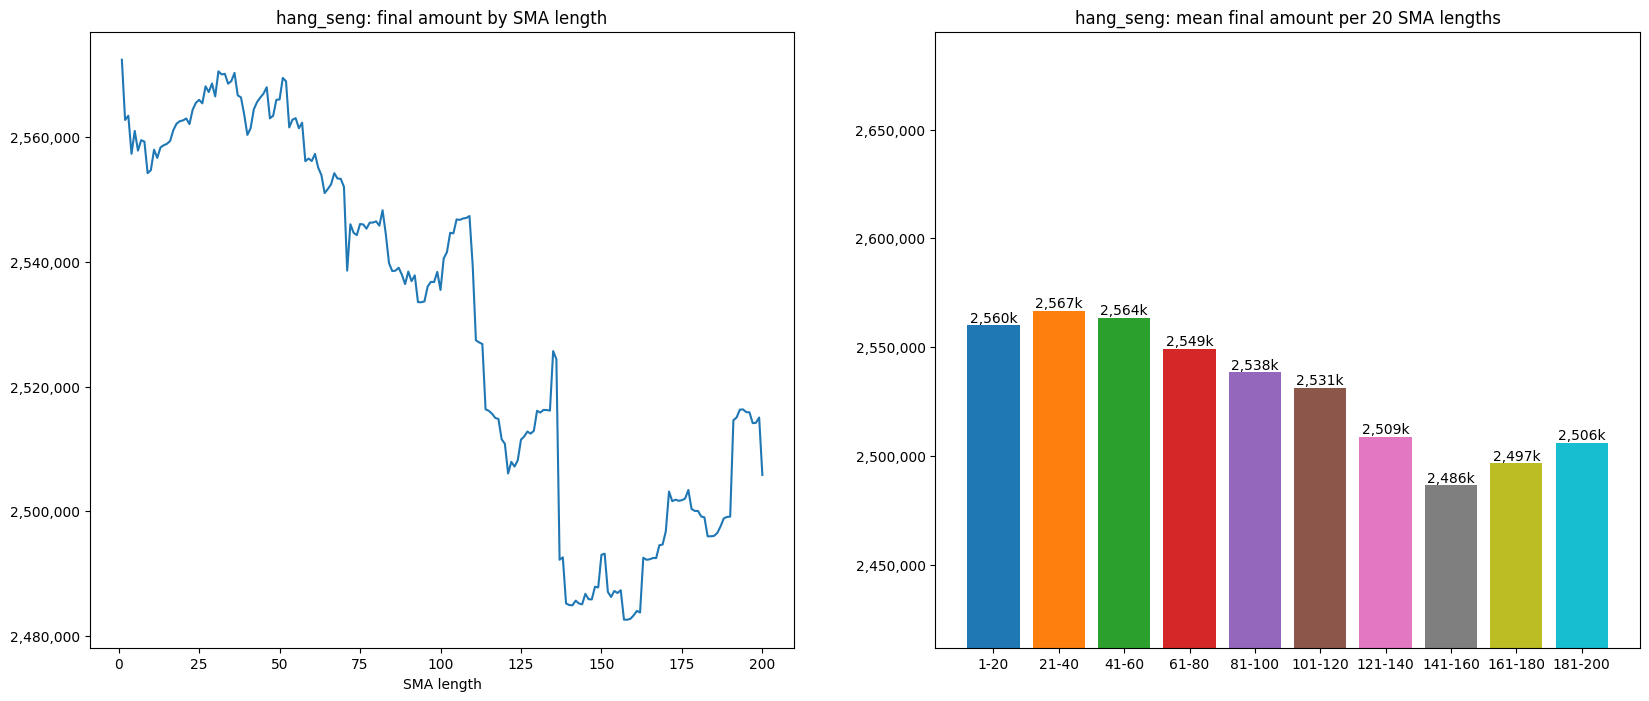

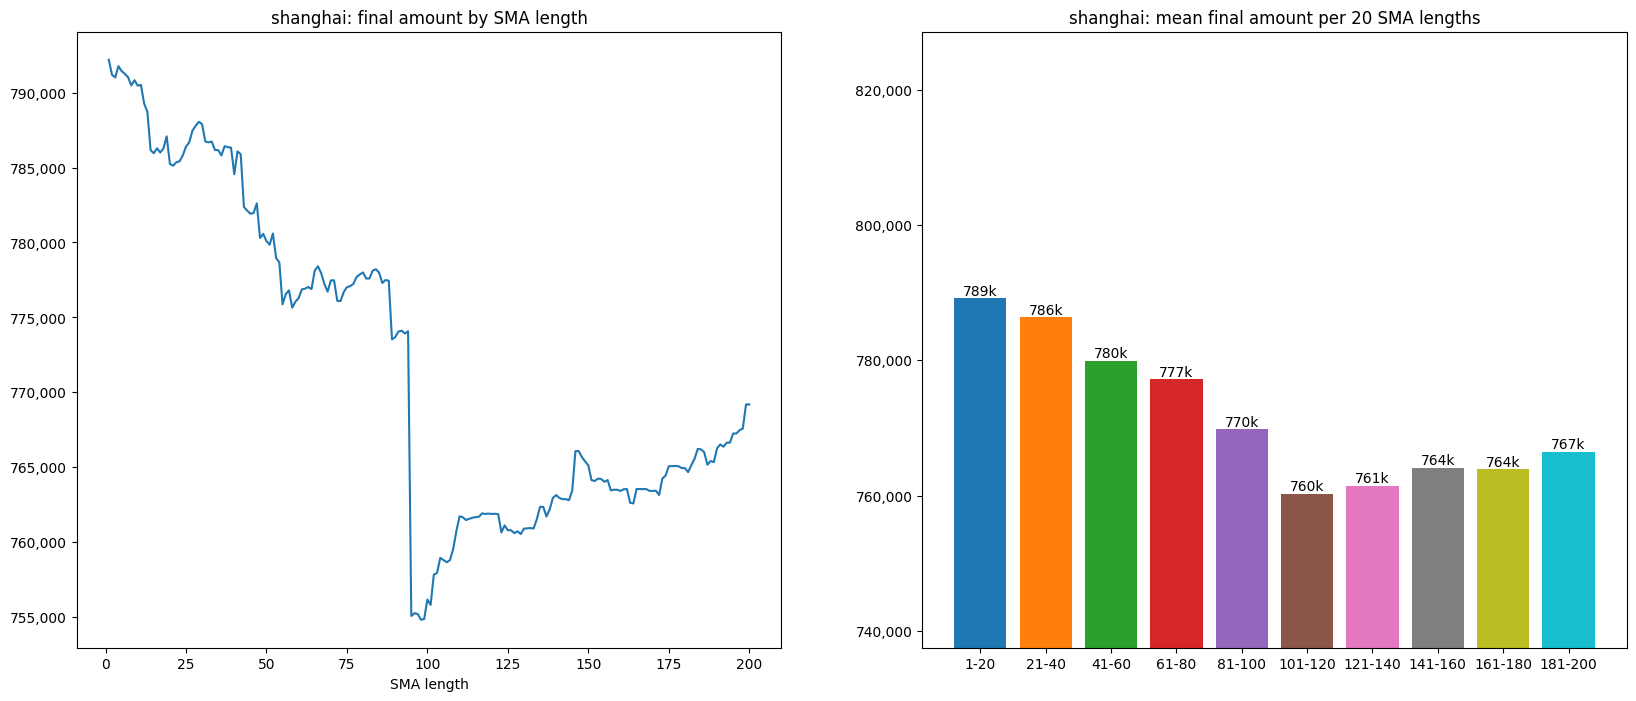

In [3]:
from pathlib import Path
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

original_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/raw")

processed_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/processed")


original_data_path.mkdir(parents=True, exist_ok=True) # exists is if does not exist create else ignore parents is the same for folders above it so in this case data

processed_data_path.mkdir(parents=True, exist_ok=True)


SMA_LENGTHS = [50, 100, 200]

indices = {
    "sp500": "^GSPC",
    "nasdaq_comp": "^IXIC",
    "nasdaq100": "^NDX",
    "ftse100": "^FTSE",
    "nikkei": "^N225",
    "dax": "^GDAXI",
    "cac40": "^FCHI",
    "hang_seng": "^HSI",
    "shanghai": "000001.SS",
}

PAYMENT = 1000
INTEREST_RATE = 0.02
START_DATE = "1986-01-01"

DIV_YIELD = {  # placeholders, adjust manually; dax is 0 because it is already total return
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
}

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
          "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]

def sma_calc(df):
    for length in SMA_LENGTHS:
        df[f"sma_{length}"] = df["Close"].rolling(window=length).mean()
    return df

def pct(value, base):  # how many % value is above (+) or below (-) base
    return (value / base - 1) * 100

def simulate(df, sma_col, dividend_yield):
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    smas = df[sma_col].tolist()

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available
    start = df.index.get_loc(valid.index[0])

    cash = 0
    units = 0
    last_month = dates[start].month  # the first payment arrives in the next month

    for i in range(start, len(df)):
        days = (dates[i] - dates[i - 1]).days
        cash *= (1 + INTEREST_RATE) ** (days / 365)  # interest on the cash
        units *= (1 + dividend_yield) ** (days / 365)  # dividends reinvested

        if dates[i].month != last_month:  # first trading day of a new month: payment arrives
            cash += PAYMENT
            last_month = dates[i].month

        if cash > 0 and closes[i - 1] <= smas[i - 1]:  # yesterday's close was at or below yesterday's sma: buy with all the cash
            units += cash / closes[i]
            cash = 0

    return units * closes[-1] + cash  # final amount = everything invested + leftover cash

for name, ticker in indices.items():
    df = yf.download(ticker, start="1950-01-01", progress=False) # progress is a progress bar that shows the download progress

    df.columns = df.columns.get_level_values(0)  # df.columns.get_level_values(0) keeps only the first layer, so the columns become plain names basically nested we want the first layer which is the name of the columns
    df.to_csv(original_data_path / f"{name}_raw.csv")

    gaps = df.index.to_series().diff().dt.days # calculates gap . index is date series turns it to list of values diff subtracts previous row and dt days keeps number of days between the two dates

    print(name, df.index.min().date(), df.index.max().date(), len(df),
          "// duplicates:", df.index.duplicated().sum(),
          "// NaN cells:", df.isna().sum().sum(),
          "// longest gap (in days):", gaps.max())

    df = df.dropna(subset=["Close"])  # drops rows with no price (Yahoo can add an empty last row)
    df = sma_calc(df)

    df.to_csv(processed_data_path / f"{name}_processed.csv")

    final_values = []  # final_values[0] is sma_1 (DCA), final_values[199] is sma_200
    for n in range(1, 201):
        df["sma_n"] = df["Close"].rolling(window=n).mean()
        final_values.append(simulate(df, "sma_n", DIV_YIELD[name]))

    group_names = []
    group_means = []
    group_labels = []
    for first in range(1, 200, 20):
        group = final_values[first - 1:first + 19]
        mean = sum(group) / len(group)
        group_names.append(f"{first}-{first + 19}")
        group_means.append(mean)
        group_labels.append(f"{mean / 1000:,.0f}k")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    ax1.plot(range(1, 201), final_values)
    ax1.set_title(f"{name}: final amount by SMA length")
    ax1.set_xlabel("SMA length")
    ax1.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    bars = ax2.bar(group_names, group_means, color=colors)
    ax2.bar_label(bars, labels=group_labels)
    ax2.set_ylim(bottom=min(group_means) * 0.97)
    ax2.set_title(f"{name}: mean final amount per 20 SMA lengths")
    ax2.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    dca = final_values[0]  # n=1 is DCA
    others = final_values[1:]  # n=2 to 200
    best = max(others)
    worst = min(others)
    beat = 0
    for value in others:
        if value > dca:
            beat += 1

    print(name, "// DCA:", f"{dca:,.0f}",
          "// SMA50:", f"{pct(final_values[49], dca):+.2f}%",
          "// SMA100:", f"{pct(final_values[99], dca):+.2f}%",
          "// SMA200:", f"{pct(final_values[199], dca):+.2f}%",
          "// average n=2-200:", f"{pct(sum(others) / len(others), dca):+.2f}%",
          "// best n:", others.index(best) + 2, f"{pct(best, dca):+.2f}%",
          "// worst n:", others.index(worst) + 2, f"{pct(worst, dca):+.2f}%",
          "// lengths that beat DCA:", beat, "of 199")

    print("   group means vs DCA:", end=" ")
    for group_name, mean in zip(group_names, group_means):
        print(f"{group_name}: {pct(mean, dca):+.2f}%", end=" | ")
    print()

    ranking = []
    for n in range(1, 201):
        ranking.append((final_values[n - 1], n))
    ranking.sort(reverse=True)  # biggest final amount first

    print(name, "// top 10 SMA lengths by final amount (sma_1 is DCA)")
    print("   rank  sma         final amount")
    for i in range(10):
        value, n = ranking[i]
        print(f"   {i + 1:>4}  sma_{n:<4} {value:>14,.0f}")

plt.show()

# SMA Results

## S&P 500 (`sp500`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | sp500 |
| Start date | 1950-01-03 |
| End date | 2026-10-14 |
| Observations | 19318 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 7.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 8,251,970 |
| SMA50 | -0.21% |
| SMA100 | -0.87% |
| SMA200 | -1.37% |
| average n=2-200 | -0.75% |
| best n | 10 +0.13% |
| worst n | 182 -1.89% |
| lengths that beat DCA | 11 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | +0.00% |
| 21-40 | -0.14% |
| 41-60 | -0.16% |
| 61-80 | -0.58% |
| 81-100 | -0.95% |
| 101-120 | -1.13% |
| 121-140 | -0.91% |
| 141-160 | -0.78% |
| 161-180 | -1.28% |
| 181-200 | -1.49% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_10 | 8,262,893 |
| 2 | sma_9 | 8,259,227 |
| 3 | sma_11 | 8,257,011 |
| 4 | sma_12 | 8,254,553 |
| 5 | sma_16 | 8,254,354 |
| 6 | sma_8 | 8,253,492 |
| 7 | sma_3 | 8,253,489 |
| 8 | sma_20 | 8,252,980 |
| 9 | sma_22 | 8,252,466 |
| 10 | sma_21 | 8,252,246 |

## Nasdaq Composite (`nasdaq_comp`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | nasdaq_comp |
| Start date | 1971-02-05 |
| End date | 2026-10-14 |
| Observations | 14040 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 7.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 13,342,712 |
| SMA50 | -0.78% |
| SMA100 | -0.91% |
| SMA200 | -0.57% |
| average n=2-200 | -0.99% |
| best n | 2 -0.23% |
| worst n | 67 -1.69% |
| lengths that beat DCA | 0 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | -0.36% |
| 21-40 | -0.90% |
| 41-60 | -0.83% |
| 61-80 | -1.37% |
| 81-100 | -0.81% |
| 101-120 | -1.04% |
| 121-140 | -1.28% |
| 141-160 | -1.18% |
| 161-180 | -1.24% |
| 181-200 | -0.88% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_1 | 13,342,712 |
| 2 | sma_2 | 13,312,031 |
| 3 | sma_3 | 13,310,787 |
| 4 | sma_5 | 13,303,641 |
| 5 | sma_7 | 13,302,282 |
| 6 | sma_8 | 13,300,860 |
| 7 | sma_4 | 13,298,503 |
| 8 | sma_10 | 13,296,165 |
| 9 | sma_6 | 13,295,929 |
| 10 | sma_9 | 13,292,179 |

## Nasdaq-100 (`nasdaq100`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | nasdaq100 |
| Start date | 1985-10-01 |
| End date | 2026-10-14 |
| Observations | 10339 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 7.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 25,790,789 |
| SMA50 | -0.83% |
| SMA100 | -1.17% |
| SMA200 | +0.92% |
| average n=2-200 | -0.56% |
| best n | 200 +0.92% |
| worst n | 158 -1.98% |
| lengths that beat DCA | 38 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | -0.19% |
| 21-40 | -0.15% |
| 41-60 | -0.67% |
| 61-80 | -0.79% |
| 81-100 | -1.25% |
| 101-120 | -0.58% |
| 121-140 | -0.81% |
| 141-160 | -1.77% |
| 161-180 | +0.00% |
| 181-200 | +0.61% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_200 | 26,028,626 |
| 2 | sma_199 | 26,028,291 |
| 3 | sma_196 | 25,965,121 |
| 4 | sma_195 | 25,964,974 |
| 5 | sma_194 | 25,963,580 |
| 6 | sma_193 | 25,963,188 |
| 7 | sma_198 | 25,963,063 |
| 8 | sma_197 | 25,962,952 |
| 9 | sma_180 | 25,958,205 |
| 10 | sma_181 | 25,954,636 |

## FTSE 100 (`ftse100`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | ftse100 |
| Start date | 1984-01-03 |
| End date | 2026-10-15 |
| Observations | 10809 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 5.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 3,730,816 |
| SMA50 | +0.08% |
| SMA100 | -1.21% |
| SMA200 | -0.09% |
| average n=2-200 | -0.05% |
| best n | 184 +1.03% |
| worst n | 92 -1.42% |
| lengths that beat DCA | 96 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | -0.35% |
| 21-40 | -0.46% |
| 41-60 | -0.03% |
| 61-80 | -0.43% |
| 81-100 | -1.15% |
| 101-120 | -0.37% |
| 121-140 | +0.39% |
| 141-160 | +0.59% |
| 161-180 | +0.75% |
| 181-200 | +0.58% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_184 | 3,769,319 |
| 2 | sma_183 | 3,769,317 |
| 3 | sma_182 | 3,768,970 |
| 4 | sma_185 | 3,767,079 |
| 5 | sma_186 | 3,766,270 |
| 6 | sma_189 | 3,766,245 |
| 7 | sma_188 | 3,766,245 |
| 8 | sma_187 | 3,765,240 |
| 9 | sma_181 | 3,763,886 |
| 10 | sma_180 | 3,763,591 |

## Nikkei (`nikkei`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | nikkei |
| Start date | 1965-01-05 |
| End date | 2026-10-15 |
| Observations | 15186 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 11.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 2,336,295 |
| SMA50 | -0.34% |
| SMA100 | -0.20% |
| SMA200 | +0.35% |
| average n=2-200 | -0.13% |
| best n | 194 +0.47% |
| worst n | 38 -0.73% |
| lengths that beat DCA | 68 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | +0.03% |
| 21-40 | -0.41% |
| 41-60 | -0.41% |
| 61-80 | -0.37% |
| 81-100 | -0.29% |
| 101-120 | -0.12% |
| 121-140 | +0.05% |
| 141-160 | -0.26% |
| 161-180 | +0.12% |
| 181-200 | +0.34% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_194 | 2,347,341 |
| 2 | sma_195 | 2,347,268 |
| 3 | sma_192 | 2,347,262 |
| 4 | sma_193 | 2,347,253 |
| 5 | sma_196 | 2,345,739 |
| 6 | sma_191 | 2,345,691 |
| 7 | sma_190 | 2,345,571 |
| 8 | sma_188 | 2,345,321 |
| 9 | sma_189 | 2,345,319 |
| 10 | sma_198 | 2,345,115 |

## DAX (`dax`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | dax |
| Start date | 1987-12-30 |
| End date | 2026-10-15 |
| Observations | 9811 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 6.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 2,666,950 |
| SMA50 | -0.48% |
| SMA100 | -0.25% |
| SMA200 | -2.56% |
| average n=2-200 | -0.90% |
| best n | 3 -0.03% |
| worst n | 180 -2.74% |
| lengths that beat DCA | 0 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | -0.18% |
| 21-40 | -0.35% |
| 41-60 | -0.67% |
| 61-80 | -0.76% |
| 81-100 | -0.33% |
| 101-120 | -0.40% |
| 121-140 | -0.47% |
| 141-160 | -0.84% |
| 161-180 | -2.43% |
| 181-200 | -2.50% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_1 | 2,666,950 |
| 2 | sma_3 | 2,666,018 |
| 3 | sma_10 | 2,666,011 |
| 4 | sma_8 | 2,665,460 |
| 5 | sma_129 | 2,665,188 |
| 6 | sma_11 | 2,664,779 |
| 7 | sma_4 | 2,664,737 |
| 8 | sma_7 | 2,664,532 |
| 9 | sma_2 | 2,664,054 |
| 10 | sma_9 | 2,664,039 |

## CAC 40 (`cac40`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | cac40 |
| Start date | 1990-03-01 |
| End date | 2026-10-15 |
| Observations | 9303 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 6.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 1,827,613 |
| SMA50 | +0.16% |
| SMA100 | +0.19% |
| SMA200 | -1.23% |
| average n=2-200 | -0.04% |
| best n | 94 +0.45% |
| worst n | 197 -1.32% |
| lengths that beat DCA | 136 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | +0.10% |
| 21-40 | +0.20% |
| 41-60 | +0.13% |
| 61-80 | +0.08% |
| 81-100 | +0.21% |
| 101-120 | +0.11% |
| 121-140 | -0.10% |
| 141-160 | +0.06% |
| 161-180 | -0.25% |
| 181-200 | -0.96% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_94 | 1,835,921 |
| 2 | sma_97 | 1,835,744 |
| 3 | sma_96 | 1,835,706 |
| 4 | sma_95 | 1,835,301 |
| 5 | sma_93 | 1,833,958 |
| 6 | sma_33 | 1,833,076 |
| 7 | sma_91 | 1,832,994 |
| 8 | sma_34 | 1,832,731 |
| 9 | sma_36 | 1,832,724 |
| 10 | sma_92 | 1,832,705 |

## Hang Seng (`hang_seng`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | hang_seng |
| Start date | 1986-12-31 |
| End date | 2026-10-15 |
| Observations | 9820 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 7.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 2,572,456 |
| SMA50 | -0.25% |
| SMA100 | -1.44% |
| SMA200 | -2.59% |
| average n=2-200 | -1.63% |
| best n | 31 -0.07% |
| worst n | 158 -3.49% |
| lengths that beat DCA | 0 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | -0.48% |
| 21-40 | -0.23% |
| 41-60 | -0.35% |
| 61-80 | -0.90% |
| 81-100 | -1.33% |
| 101-120 | -1.60% |
| 121-140 | -2.47% |
| 141-160 | -3.35% |
| 161-180 | -2.95% |
| 181-200 | -2.58% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_1 | 2,572,456 |
| 2 | sma_31 | 2,570,587 |
| 3 | sma_36 | 2,570,342 |
| 4 | sma_33 | 2,570,187 |
| 5 | sma_32 | 2,570,101 |
| 6 | sma_51 | 2,569,532 |
| 7 | sma_35 | 2,569,023 |
| 8 | sma_52 | 2,569,000 |
| 9 | sma_29 | 2,568,636 |
| 10 | sma_34 | 2,568,611 |

## Shanghai (`shanghai`)

### Dataset Information

| Metric | Value |
|---|---:|
| Index | shanghai |
| Start date | 1997-07-02 |
| End date | 2026-10-15 |
| Observations | 7093 |
| Duplicates | 0 |
| NaN cells | 0 |
| Longest gap (in days) | 20.0 |

### Performance Summary

| Metric | Value |
|---|---:|
| DCA | 792,198 |
| SMA50 | -1.53% |
| SMA100 | -4.55% |
| SMA200 | -2.90% |
| average n=2-200 | -2.58% |
| best n | 4 -0.05% |
| worst n | 98 -4.72% |
| lengths that beat DCA | 0 of 199 |

### Group Means vs DCA

| SMA length group | Mean vs DCA |
|---|---:|
| 1-20 | -0.38% |
| 21-40 | -0.73% |
| 41-60 | -1.54% |
| 61-80 | -1.89% |
| 81-100 | -2.82% |
| 101-120 | -4.03% |
| 121-140 | -3.88% |
| 141-160 | -3.55% |
| 161-180 | -3.57% |
| 181-200 | -3.24% |

### Top 10 SMA Lengths by Final Amount

*sma_1 is DCA*

| Rank | SMA | Final amount |
|---:|---|---:|
| 1 | sma_1 | 792,198 |
| 2 | sma_4 | 791,768 |
| 3 | sma_5 | 791,443 |
| 4 | sma_6 | 791,254 |
| 5 | sma_2 | 791,199 |
| 6 | sma_7 | 791,032 |
| 7 | sma_3 | 791,010 |
| 8 | sma_9 | 790,831 |
| 9 | sma_11 | 790,521 |
| 10 | sma_8 | 790,482 |
